# 02 · Talent flow analysis

**Question:** which consulting suppliers attract more tech talent than they lose, and how much of that movement goes to and from other consulting firms and the automotive industry?

Data: anonymized *Company Movements* table from LinkedIn Talent Insights, 41 suppliers, 12 months up to 2023-10-18 (see notebook 01 for the quality checks).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

GREY, BLUE, RED = "#B3B3B3", "#7089AC", "#9E2A2B"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

df = pd.read_csv("../data/processed/company_movements.csv")
df["counterparty_type"] = np.select(
    [df["is_consulting"] == 1, df["is_automotive"] == 1], ["Consulting", "Automotive"], "Other")

## 1. Overall flow

In [2]:
totals = df[["departures", "hires", "net_change"]].sum()
print(f"Departures: {totals['departures']:,}   Hires: {totals['hires']:,}   Net change: {totals['net_change']:+,}")

by_type = (df.groupby("counterparty_type")[["departures", "hires", "net_change"]].sum()
             .reindex(["Consulting", "Automotive", "Other"]))
by_type["share_of_departures"] = (by_type["departures"] / totals["departures"]).round(2)
by_type

Departures: 1,649   Hires: 2,154   Net change: +505


,departures,hires,net_change,share_of_departures
counterparty_type,,,,
Consulting,343,397,54,0.21
Automotive,511,448,-63,0.31
Other,795,1309,514,0.48


A counterparty can be tagged as both consulting and automotive (for example an engineering consultancy that works for the car industry). In the table above such rows are counted as *Consulting*, so every row is counted once.

## 2. Net talent change per supplier

26 of 41 suppliers gained more people than they lost.


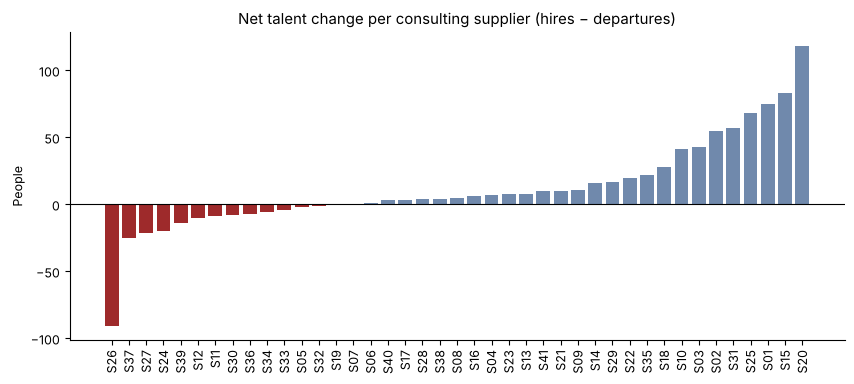

In [3]:
per_supplier = (df.groupby("supplier")[["departures", "hires", "net_change"]].sum()
                  .sort_values("net_change"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(per_supplier.index, per_supplier["net_change"],
       color=np.where(per_supplier["net_change"] < 0, RED, BLUE))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Net talent change per consulting supplier (hires − departures)")
ax.set_ylabel("People")
ax.tick_params(axis="x", rotation=90)
plt.show()

gaining = (per_supplier["net_change"] > 0).sum()
print(f"{gaining} of {len(per_supplier)} suppliers gained more people than they lost.")

In [4]:
print("Largest net loss")
per_supplier.head(5)

Largest net loss


,departures,hires,net_change
supplier,,,
S26,95,4,-91
S37,104,79,-25
S27,39,18,-21
S24,33,13,-20
S39,35,21,-14


In [5]:
print("Largest net gain")
per_supplier.tail(5).iloc[::-1]

Largest net gain


,departures,hires,net_change
supplier,,,
S20,28,146,118
S15,49,132,83
S01,46,121,75
S25,42,110,68
S31,47,104,57


## 3. Movement to and from other consulting companies and the automotive industry

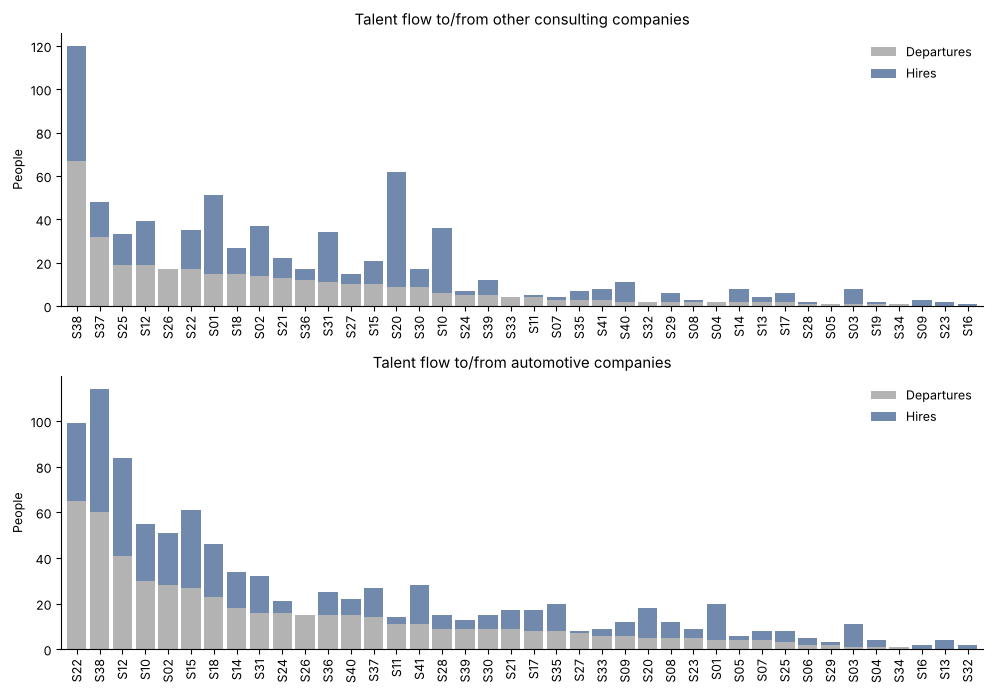

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=False)
for ax, flag, title in [(axes[0], "is_consulting", "other consulting companies"),
                        (axes[1], "is_automotive", "automotive companies")]:
    flow = (df[df[flag] == 1].groupby("supplier")[["departures", "hires"]].sum()
              .sort_values("departures", ascending=False))
    flow.plot(kind="bar", stacked=True, color=[GREY, BLUE], width=0.85, ax=ax)
    ax.set_title(f"Talent flow to/from {title}")
    ax.set_xlabel("")
    ax.set_ylabel("People")
    ax.legend(["Departures", "Hires"], frameon=False)
plt.tight_layout()
plt.show()

In [7]:
auto = df[df["is_automotive"] == 1].groupby("supplier")[["departures", "hires", "net_change"]].sum()
print("Suppliers that lose the most people to automotive companies")
auto.sort_values("departures", ascending=False).head(10)

Suppliers that lose the most people to automotive companies


,departures,hires,net_change
supplier,,,
S22,65,34,-31
S38,60,54,-6
S12,41,43,2
S10,30,25,-5
S02,28,23,-5
S15,27,34,7
S18,23,23,0
S14,18,16,-2
S31,16,16,0


In [8]:
print("Suppliers that hire the most people from automotive companies")
auto.sort_values("hires", ascending=False).head(10)

Suppliers that hire the most people from automotive companies


,departures,hires,net_change
supplier,,,
S38,60,54,-6
S12,41,43,2
S15,27,34,7
S22,65,34,-31
S10,30,25,-5
S02,28,23,-5
S18,23,23,0
S41,11,17,6
S31,16,16,0


## 4. How the measures relate to each other

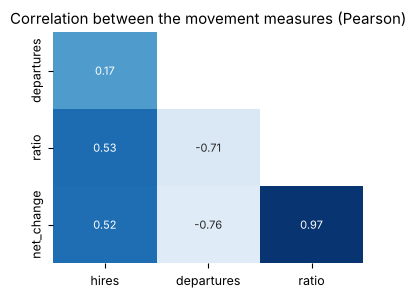

In [9]:
corr = df[["hires", "departures", "ratio", "net_change"]].corr(method="pearson").iloc[1:, :-1]
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(4, 3))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, cbar=False,
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation between the movement measures (Pearson)")
plt.show()

`ratio` and `net_change` are almost the same signal at row level, because most counterparties exchange only one or two people. In the rest of the project `net_change` and the raw counts are used, since they are easier to interpret and can be summed per supplier.

## Key findings

- Across the 41 suppliers, **2,154 people were hired and 1,649 left** (net **+505**); **26 of 41** suppliers gained more people than they lost.
- **The automotive industry is the only counterparty group the suppliers lose talent to on balance:** 511 departures vs 448 hires (net −63). Automotive companies receive about **31%** of all departures.
- Movement **between consulting companies is close to balanced** (343 departures vs 397 hires, net +54).
- One supplier, **S26, stands out:** 95 departures and only 4 hires, the largest net loss in the data.
- Totals alone do not tell whether a supplier's difference between hires and departures is larger than normal turnover. That is tested in **notebook 03**.